# 01 — Préparation des données simulées

> **SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA.** Les cinq institutions et l'indice de marché sont entièrement simulés pour illustrer la méthode. Aucune API financière n'est appelée.

Les prix sont générés avec des rendements corrélés et une volatilité GARCH-like. Le rendement logarithmique est $r_t=\log(P_t/P_{t-1})$. Les jours sont des jours ouvrés simulés, pas le calendrier officiel de la Bourse de Casablanca.

In [1]:
import numpy as np
from src.data import load_synthetic_dataset
from src.config import BANKS, SYNTHETIC_LABEL
from src.preprocessing import calculate_log_returns
from src.visualization import plot_series

prices, returns, market, dataset = load_synthetic_dataset()
calculated_returns = calculate_log_returns(prices)
print(SYNTHETIC_LABEL)
display(prices.head(), returns.describe(), dataset['stress_period'].value_counts())
assert calculated_returns.index.equals(returns.index[1:])
assert calculated_returns.columns.equals(returns.columns)
assert np.allclose(calculated_returns, returns.iloc[1:])

SYNTHETIC / SIMULATED DATA — NOT REAL MARKET DATA


,ATW_SIM,BCP_SIM,BOA_SIM,CIH_SIM,CDM_SIM
date,,,,,
2021-01-01,100.463882,100.493902,100.896558,99.556753,99.348278
2021-01-04,99.954818,100.507077,101.110658,98.948684,99.975606
2021-01-05,101.414575,102.191167,102.140495,100.132006,99.974170
2021-01-06,99.261141,101.528098,101.604159,99.547484,99.462968
2021-01-07,100.358342,101.335596,100.120142,100.092807,99.001401


,ATW_SIM,BCP_SIM,BOA_SIM,CIH_SIM,CDM_SIM
count,1304.000000,1304.000000,1304.000000,1304.000000,1304.000000
mean,-0.000576,-0.000163,-0.000287,-0.000807,-0.000685
std,0.012102,0.013536,0.013872,0.015815,0.015915
min,-0.087509,-0.054796,-0.069541,-0.072913,-0.078747
25%,-0.006932,-0.008839,-0.008486,-0.010720,-0.010019
50%,-0.000613,0.000285,-0.000440,-0.000107,-0.000241
75%,0.006468,0.008212,0.008747,0.009609,0.009167
max,0.069040,0.043919,0.044268,0.068103,0.077633


stress_period
False    1161
True      143
Name: count, dtype: int64

Les quatre CSV canoniques sont conservés dans `data/synthetic/`. Le chargement ne remplace pas un jeu existant; la graine fixe est `20251115`. L'alignement se fait sur les dates communes et les rendements manquants de début de série sont supprimés.

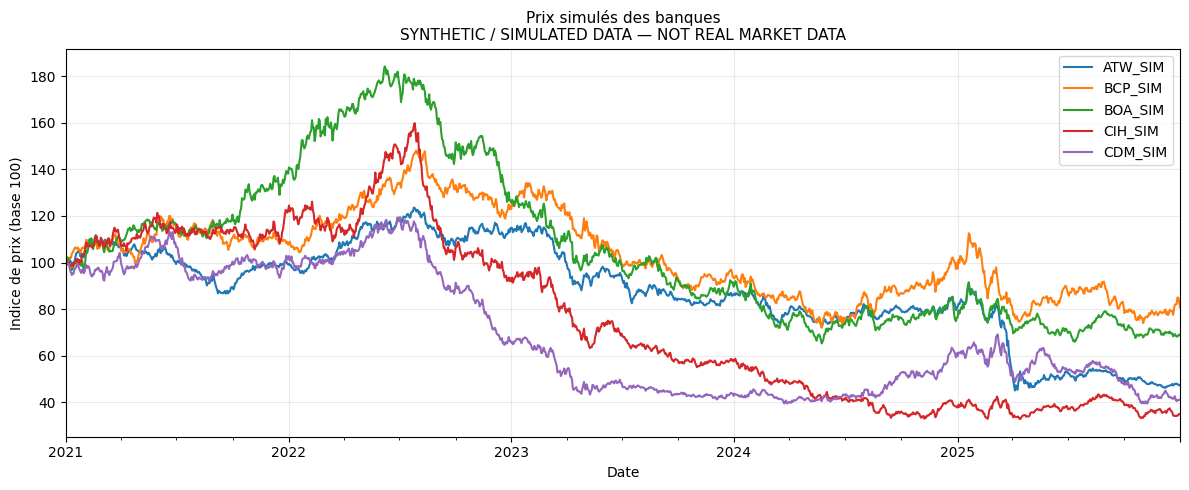

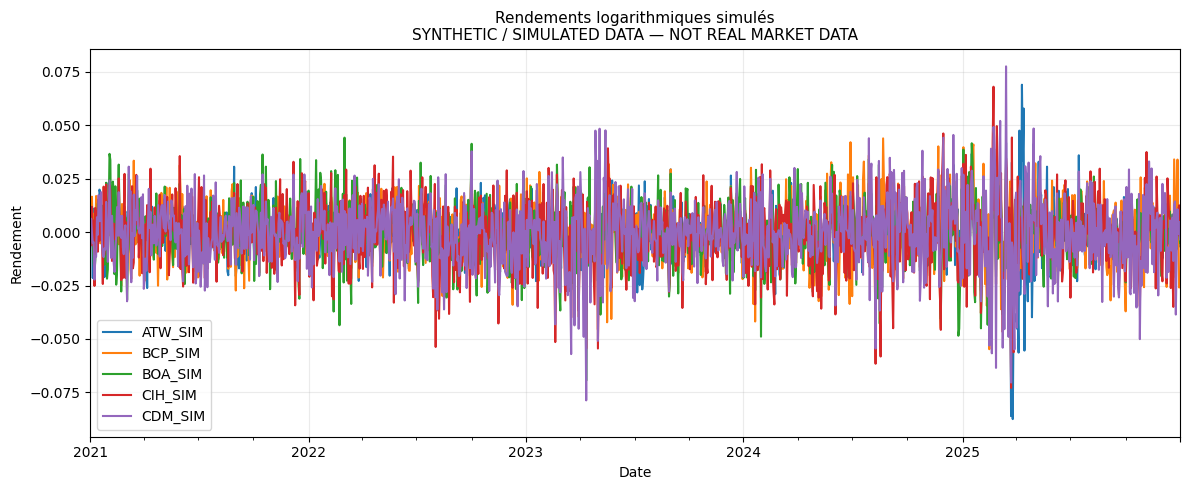

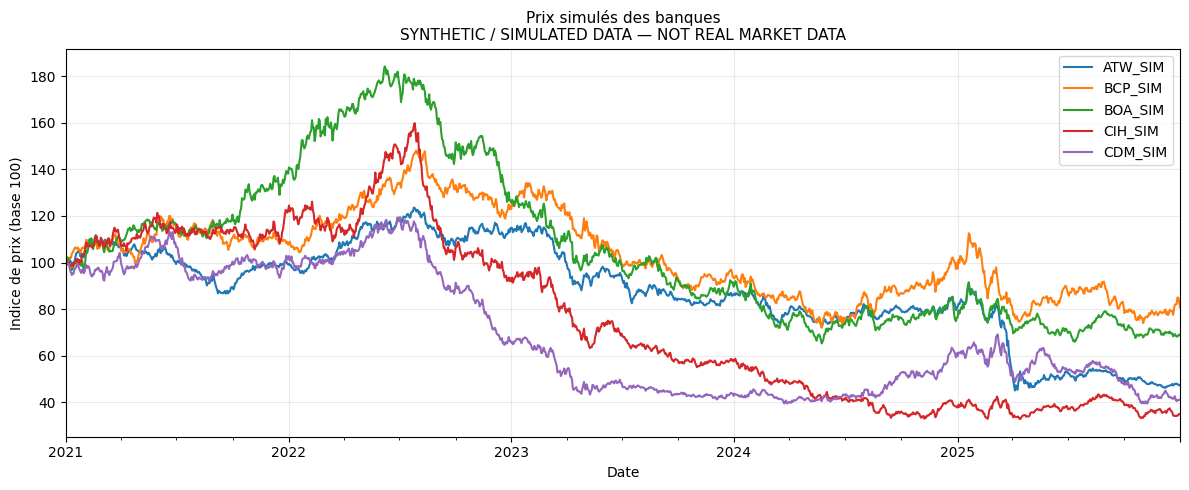

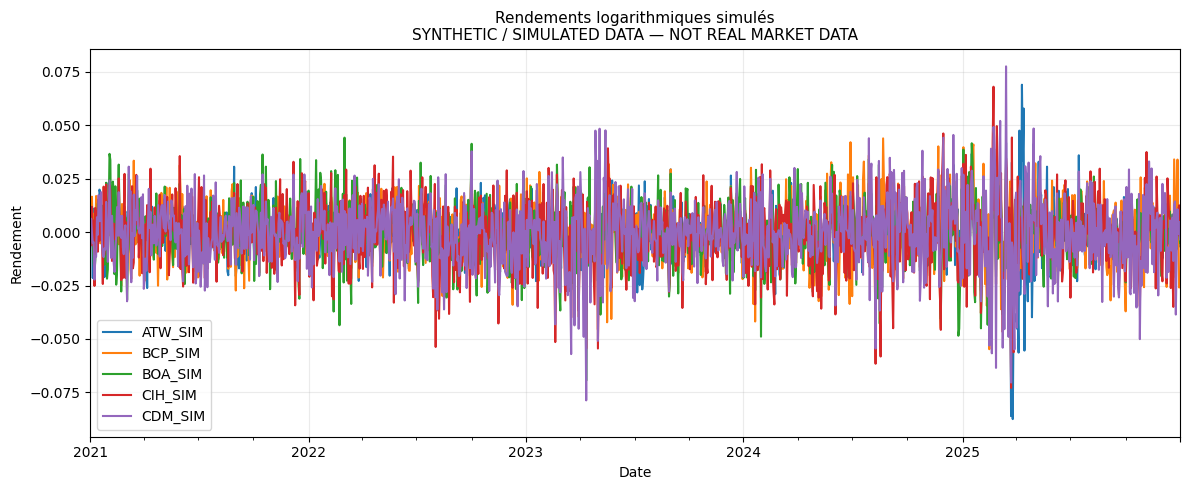

In [2]:
fig = plot_series(prices, 'Prix simulés des banques', 'Indice de prix (base 100)')
display(fig)
fig = plot_series(returns, 'Rendements logarithmiques simulés', 'Rendement')
display(fig)